<a href="https://colab.research.google.com/github/PanwarParth1/Kaggle-ML-Projects/blob/main/Predictive_Maintenance_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predictive Maintenance - Machine Failure Prediction
**Target:** `Target` (0 = No Failure, 1 = Failure)

In [2]:
try:
    from google.colab import files
    a = files.upload()
except ImportError:
    pass

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
Machine_data = pd.read_csv("predictive_maintenance.csv")
Machine_data

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure
...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,No Failure
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,No Failure
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,No Failure
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,No Failure


In [5]:
Machine_data.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


In [6]:
print(Machine_data["Target"].value_counts())
print()
print(Machine_data["Failure Type"].value_counts())

Target
0    9661
1     339
Name: count, dtype: int64

Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64


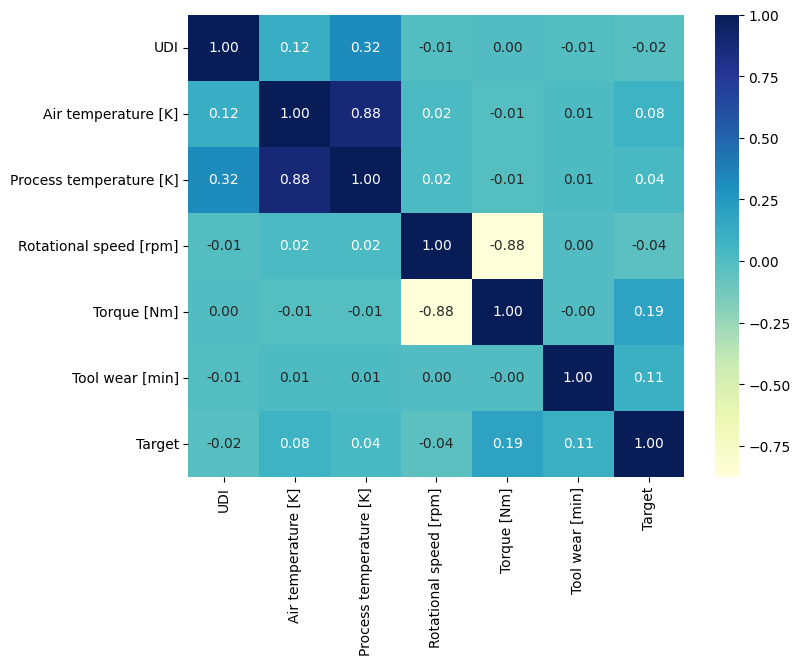

In [7]:
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(Machine_data.select_dtypes(include=[np.number]).corr(), annot=True, cmap='YlGnBu', fmt='.2f')
plt.show()

## Train / Test split

In [8]:
from sklearn.model_selection import StratifiedShuffleSplit
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for train_indices, test_indices in split.split(Machine_data, Machine_data[["Target", "Type"]]):
    strat_train_set = Machine_data.iloc[train_indices].copy()
    strat_test_set = Machine_data.iloc[test_indices].copy()
print(len(strat_train_set), len(strat_test_set))

8000 2000


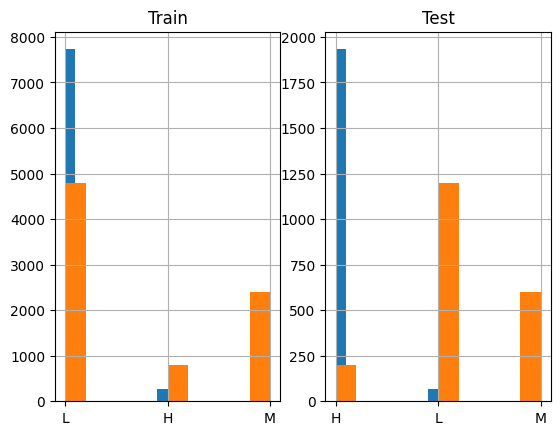

In [9]:
plt.subplot(1,2,1)
strat_train_set["Target"].hist()
strat_train_set["Type"].hist()
plt.title("Train")

plt.subplot(1,2,2)
strat_test_set["Target"].hist()
strat_test_set["Type"].hist()
plt.title("Test")
plt.show()

In [10]:
strat_train_set.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8000 entries, 2790 to 8662
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      8000 non-null   int64  
 1   Product ID               8000 non-null   object 
 2   Type                     8000 non-null   object 
 3   Air temperature [K]      8000 non-null   float64
 4   Process temperature [K]  8000 non-null   float64
 5   Rotational speed [rpm]   8000 non-null   int64  
 6   Torque [Nm]              8000 non-null   float64
 7   Tool wear [min]          8000 non-null   int64  
 8   Target                   8000 non-null   int64  
 9   Failure Type             8000 non-null   object 
dtypes: float64(3), int64(4), object(3)
memory usage: 687.5+ KB


## Custom transformers
- `NullImputer`: agar numeric columns me missing value ho to median se bhar deta hai (fit me train ka median seekhta hai)
- `FeatureEncoder`: `Type` (L/M/H) ko one-hot encode karta hai
- `FeatureDropper`: unnecessary columns hatata hai. **`Failure Type` bhi drop hota hai** kyunki ye answer ka hi hissa hai (data leakage).

In [11]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer

NUM_COLS = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]",
            "Torque [Nm]", "Tool wear [min]"]

class NullImputer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.imputer_ = SimpleImputer(strategy="median").fit(X[NUM_COLS])
        return self

    def transform(self, X):
        X = X.copy()
        X[NUM_COLS] = self.imputer_.transform(X[NUM_COLS])
        return X

In [12]:
from sklearn.preprocessing import OneHotEncoder

class FeatureEncoder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.encoder_ = OneHotEncoder(handle_unknown="ignore").fit(X[["Type"]])
        self.column_names_ = ["Type_" + c for c in self.encoder_.categories_[0]]
        return self

    def transform(self, X):
        X = X.copy()
        matrix = self.encoder_.transform(X[["Type"]]).toarray()
        for i, name in enumerate(self.column_names_):
            X[name] = matrix[:, i]
        return X

In [13]:
class FeatureDropper(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.is_fitted_ = True
        return self
    def transform(self, X):
        return X.drop(["UDI", "Product ID", "Type", "Failure Type"], axis=1, errors="ignore")

In [14]:
from sklearn.pipeline import Pipeline
pipeline = Pipeline([("nullimputer", NullImputer()),
                     ("Featureencoder", FeatureEncoder()),
                     ("FeatureDropper", FeatureDropper())])

In [15]:
strat_train_set = pipeline.fit_transform(strat_train_set)

In [16]:
strat_train_set

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Type_H,Type_L,Type_M
2790,300.4,309.6,1356.0,45.9,64.0,0,0.0,1.0,0.0
4651,303.2,311.4,1349.0,51.1,9.0,1,0.0,1.0,0.0
1171,297.0,308.1,1517.0,41.4,222.0,0,1.0,0.0,0.0
8198,299.3,310.7,1374.0,48.9,222.0,0,0.0,0.0,1.0
9887,298.8,309.5,1368.0,44.7,147.0,0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...
2353,299.2,308.4,1841.0,22.8,40.0,0,0.0,1.0,0.0
5376,302.8,312.3,1336.0,57.5,187.0,0,1.0,0.0,0.0
4257,302.6,311.0,1589.0,39.0,122.0,0,0.0,0.0,1.0
1077,296.8,307.6,1547.0,36.5,179.0,0,0.0,1.0,0.0


In [17]:
strat_train_set.isnull().sum()

,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Target,0
Type_H,0
Type_L,0
Type_M,0


## Scaling

In [18]:
from sklearn.preprocessing import StandardScaler
X = strat_train_set.drop("Target", axis=1)
y = strat_train_set["Target"]
scaler = StandardScaler()
X_data = scaler.fit_transform(X)
Y_data = y.to_numpy()

In [19]:
X_data

array([[ 0.19670135, -0.27603197, -1.0333097 , ..., -0.33402734,
         0.81649658, -0.65406921],
       [ 1.59884948,  0.94127131, -1.0728106 , ..., -0.33402734,
         0.81649658, -0.65406921],
       [-1.50590709, -1.29045138, -0.12478899, ...,  2.99376687,
        -1.22474487, -0.65406921],
       ...,
       [ 1.29838917,  0.67075947,  0.28150599, ..., -0.33402734,
        -1.22474487,  1.52889019],
       [-1.60606053, -1.62859118,  0.04450059, ..., -0.33402734,
         0.81649658, -0.65406921],
       [-1.2555235 , -0.95231158, -0.14171794, ..., -0.33402734,
         0.81649658, -0.65406921]])

## Model training (RandomForest + GridSearchCV)


In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
clf = RandomForestClassifier(class_weight="balanced", random_state=42)
param_grid = [
    {"n_estimators": [100, 200, 300], "max_depth": [None, 5, 10], "min_samples_split": [2, 4]}
]

grid_search = GridSearchCV(clf, param_grid, cv=3, scoring="f1", return_train_score=True, n_jobs=-1)
grid_search.fit(X_data, Y_data)

GridSearchCV(cv=3,
             estimator=RandomForestClassifier(class_weight='balanced',
                                              random_state=42),
             n_jobs=-1,
             param_grid=[{'max_depth': [None, 5, 10],
                          'min_samples_split': [2, 4],
                          'n_estimators': [100, 200, 300]}],
             return_train_score=True, scoring='f1')

In [21]:
print("Best params:", grid_search.best_params_)
print("Best CV F1 :", round(grid_search.best_score_, 4))

Best params: {'max_depth': 10, 'min_samples_split': 4, 'n_estimators': 100}
Best CV F1 : 0.5888


In [22]:
final_clf = grid_search.best_estimator_

In [23]:
final_clf

RandomForestClassifier(class_weight='balanced', max_depth=10,
                       min_samples_split=4, random_state=42)

In [24]:
strat_test_set = pipeline.transform(strat_test_set)
strat_test_set

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Type_H,Type_L,Type_M
5356,303.3,312.6,1692.0,29.0,125.0,0,1.0,0.0,0.0
2252,299.1,308.3,1451.0,42.8,21.0,0,1.0,0.0,0.0
9727,298.8,309.8,1461.0,39.4,141.0,0,0.0,1.0,0.0
5528,302.4,311.8,1384.0,50.9,99.0,0,0.0,1.0,0.0
1663,298.1,307.9,1759.0,28.6,176.0,0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...
9823,298.5,309.3,1488.0,43.7,189.0,0,0.0,0.0,1.0
6982,300.7,311.1,1440.0,43.0,148.0,0,0.0,1.0,0.0
7062,300.6,310.4,1407.0,51.1,157.0,0,0.0,0.0,1.0
3749,302.4,311.1,1652.0,33.9,139.0,0,0.0,1.0,0.0


In [25]:
X_test = strat_test_set.drop("Target", axis=1)
Y_test = strat_test_set["Target"]

X_test_data = scaler.transform(X_test)
Y_test_data = Y_test.to_numpy()

In [26]:
final_clf.score(X_test_data, Y_test_data)

0.974

              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.61      0.63      0.62        68

    accuracy                           0.97      2000
   macro avg       0.80      0.81      0.80      2000
weighted avg       0.97      0.97      0.97      2000

ROC-AUC: 0.9594


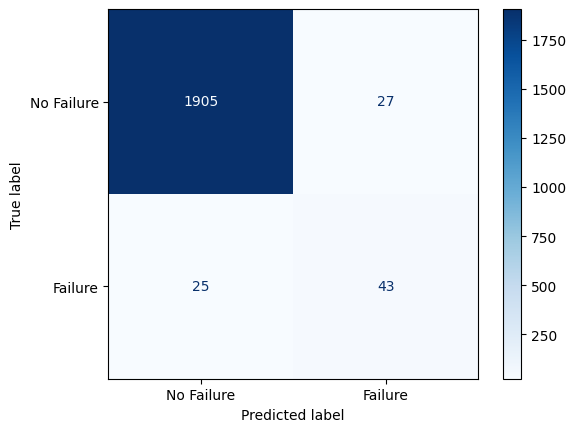

In [27]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
test_pred = final_clf.predict(X_test_data)
print(classification_report(Y_test_data, test_pred, target_names=["No Failure", "Failure"]))
print("ROC-AUC:", round(roc_auc_score(Y_test_data, final_clf.predict_proba(X_test_data)[:, 1]), 4))
ConfusionMatrixDisplay(confusion_matrix(Y_test_data, test_pred), display_labels=["No Failure", "Failure"]).plot(cmap="Blues")
plt.show()

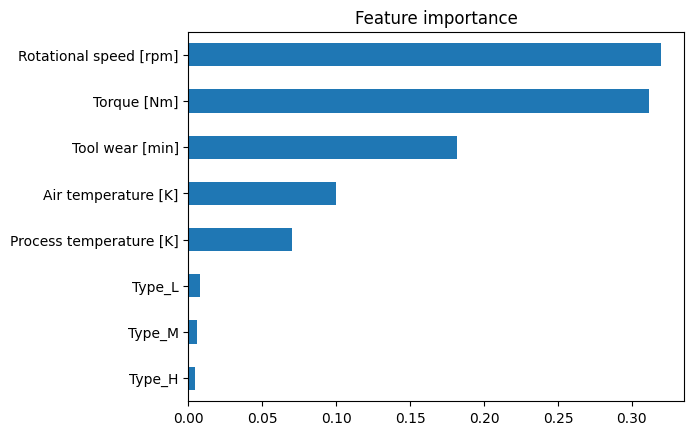

In [28]:
imp = pd.Series(final_clf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", title="Feature importance")
plt.show()

In [29]:
final_data = pipeline.fit_transform(Machine_data)
final_data

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Type_H,Type_L,Type_M
0,298.1,308.6,1551.0,42.8,0.0,0,0.0,0.0,1.0
1,298.2,308.7,1408.0,46.3,3.0,0,0.0,1.0,0.0
2,298.1,308.5,1498.0,49.4,5.0,0,0.0,1.0,0.0
3,298.2,308.6,1433.0,39.5,7.0,0,0.0,1.0,0.0
4,298.2,308.7,1408.0,40.0,9.0,0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...
9995,298.8,308.4,1604.0,29.5,14.0,0,0.0,0.0,1.0
9996,298.9,308.4,1632.0,31.8,17.0,0,1.0,0.0,0.0
9997,299.0,308.6,1645.0,33.4,22.0,0,0.0,0.0,1.0
9998,299.0,308.7,1408.0,48.5,25.0,0,1.0,0.0,0.0


In [30]:
X_final = final_data.drop("Target", axis=1)
Y_final = final_data["Target"]
scaler = StandardScaler()
X_final_data = scaler.fit_transform(X_final)
Y_final_data = Y_final.to_numpy()

In [31]:
prod_clf = RandomForestClassifier(class_weight="balanced", random_state=42)
param_grid = [
    {"n_estimators": [100, 200, 300], "max_depth": [None, 5, 10], "min_samples_split": [2, 4]}
]

grid_search = GridSearchCV(prod_clf, param_grid, cv=3, scoring="f1", return_train_score=True, n_jobs=-1)
grid_search.fit(X_final_data, Y_final_data)

GridSearchCV(cv=3,
             estimator=RandomForestClassifier(class_weight='balanced',
                                              random_state=42),
             n_jobs=-1,
             param_grid=[{'max_depth': [None, 5, 10],
                          'min_samples_split': [2, 4],
                          'n_estimators': [100, 200, 300]}],
             return_train_score=True, scoring='f1')

In [32]:
prod_final_clf = grid_search.best_estimator_

In [33]:
prod_final_clf

RandomForestClassifier(class_weight='balanced', max_depth=5, n_estimators=300,
                       random_state=42)

In [34]:
test_raw = Machine_data.iloc[test_indices].copy()      # original (untransformed) test rows
predictions = final_clf.predict(X_test_data)
probability = final_clf.predict_proba(X_test_data)[:, 1]

final_df = pd.DataFrame({"UDI": test_raw["UDI"].values,
                         "Product ID": test_raw["Product ID"].values,
                         "Actual": Y_test_data,
                         "Predicted": predictions,
                         "Failure_Probability": probability.round(3)})
final_df.to_csv("predictions.csv", index=False)

In [35]:
final_df

,UDI,Product ID,Actual,Predicted,Failure_Probability
0,5357,H34770,0,0,0.001
1,2253,H31666,0,0,0.005
2,9728,L56907,0,0,0.021
3,5529,L52708,0,0,0.084
4,1664,M16523,0,0,0.035
...,...,...,...,...,...
1995,9824,M24683,0,0,0.021
1996,6983,L54162,0,0,0.029
1997,7063,M21922,0,0,0.026
1998,3750,L50929,0,0,0.002


In [36]:
final_df[final_df['Predicted'] == 1].head(20)

,UDI,Product ID,Actual,Predicted,Failure_Probability
23,9415,L56594,1,1,0.743
33,9668,L56847,1,1,0.612
49,5693,M20552,0,1,0.685
88,8438,L55617,1,1,0.720
93,5562,M20421,0,1,0.661
111,195,M15054,1,1,0.649
144,3499,L50678,0,1,0.757
177,4559,L51738,1,1,0.828
201,1162,L48341,1,1,0.664
210,4232,L51411,0,1,0.861


In [37]:
def predict_failure(machine_type, air_temp, process_temp, rpm, torque, tool_wear):
    new = pd.DataFrame([{"UDI": 0, "Product ID": "NEW", "Type": machine_type,
                         "Air temperature [K]": air_temp, "Process temperature [K]": process_temp,
                         "Rotational speed [rpm]": rpm, "Torque [Nm]": torque,
                         "Tool wear [min]": tool_wear, "Target": 0, "Failure Type": "No Failure"}])
    X_new = scaler.transform(pipeline.transform(new).drop("Target", axis=1))
    p = prod_final_clf.predict_proba(X_new)[0, 1]
    print(f"Failure probability: {p:.1%} ->", "FAILURE LIKELY" if p >= 0.5 else "Machine OK")

predict_failure("L", 298.1, 308.6, 1551, 42.8, 0)
predict_failure("L", 300.0, 311.0, 1300, 65.0, 230)

Failure probability: 9.6% -> Machine OK
Failure probability: 94.0% -> FAILURE LIKELY
